In [255]:
from astropy.table import Table, setdiff,join
from matplotlib import pyplot as plt
import numpy as np

In [458]:
alma_regions = Table.read('../output/tables/glimpse_s07/alma_regions_YSO.tbl',format='ascii.ipac')

class_I_60 = []
class_II_60 = []
#print(spitzer_sources['p1_class_I'][alma_regions['p1_class_I'] > 0])
class_0_20 = []
class_I_20 = []
class_II_20 = []

SURFD_to_nH2 = (
        
        6.022e23  # Avogadro's constant (N_A) [particles/mol]
        / 2.016  # molecular mass of n(H2) [g/mol]
    )


for region in alma_regions:

        L_M = np.log10(region['LUM'] / region['MASS'])
        L = region['LUM']
        M = region['MASS']
        dist = region['DIST_AG']
        T = region['TBOL']
        NH_2 = region['NODEC_SURFD']*SURFD_to_nH2

        #if region['class_I_60'] != 0 and region['class_I_60'] != 1:
        class_I_60.append([L_M,L,M,dist,T,NH_2, region['rat_class_I_60']*100])
        #if region['class_II_60'] != 0 and region['class_II_60'] != 1:
        class_II_60.append([L_M,L,M,dist,T,NH_2, region['rat_class_II_60']*100])
        #if region['class_0_20'] != 0:
        class_0_20.append([L_M,L,M,dist,T,NH_2, region['rat_class_0_20']*100])
        #if region['class_I_20'] != 0:
        class_I_20.append([L_M,L,M,dist,T,NH_2, region['rat_class_I_20']*100])
        #if region['class_II_20'] != 0:
        class_II_20.append([L_M,L,M,dist,T,NH_2, region['rat_class_II_20']*100])

In [ ]:
alma_sources = Table.read('../output/tables/glimpse_s07/alma_sources_to_analyze.tbl',format='ascii.ipac')

print(alma_sources)

 ID       CLUMP            X         Y     ... p1_class_I p1_class_II p1_noclass
--- ------------------ --------- --------- ... ---------- ----------- ----------
  1             100132 897.03558  807.0044 ...         --          --         --
  2             100132 796.61502 862.99532 ...         --          --         --
  4             100244 468.07833 931.00007 ...         --          --         --
  1             100309 768.08734 459.99554 ...         --          --         --
  4             100309 637.45593 672.99884 ...         --          --         --
  8             100309 712.37732  683.0011 ...         --          --         --
  9             100309  642.2586 684.00324 ...         --          --         --
 10             100309 608.64019 683.00097 ...         --          --         --
 12             100309 696.04825 692.00105 ...         --          --         --
 16             100309 620.16646 729.99563 ...         --          --         --
...                ...      

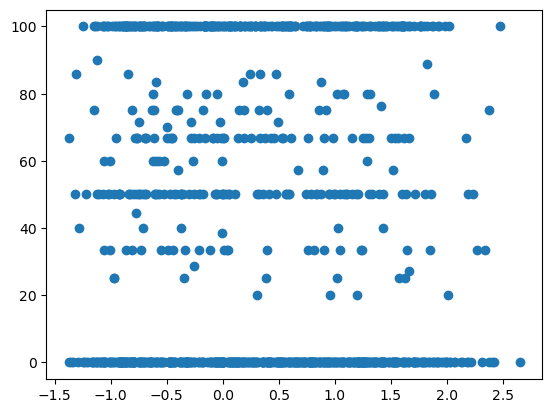

In [400]:
fig, ax = plt.subplots()

data_1 = [[x[0] for x in class_I_60],[x[-1] for x in class_I_60]]
data_2 = [[x[0] for x in class_II_60],[x[-1] for x in class_II_60]]
data_3 = [[x[0] for x in class_0_20],[x[-1] for x in class_0_20]]
data_4 = [[x[0] for x in class_I_20],[x[-1] for x in class_I_20]]
data_5 = [[x[0] for x in class_II_20],[x[-1] for x in class_II_20]]
ax.scatter(data_1[0],data_1[1])
#ax.scatter(data_2[0],data_2[1])

-1.371926893096385
2.6490899105719588
-1.371926893096385
2.6490899105719588


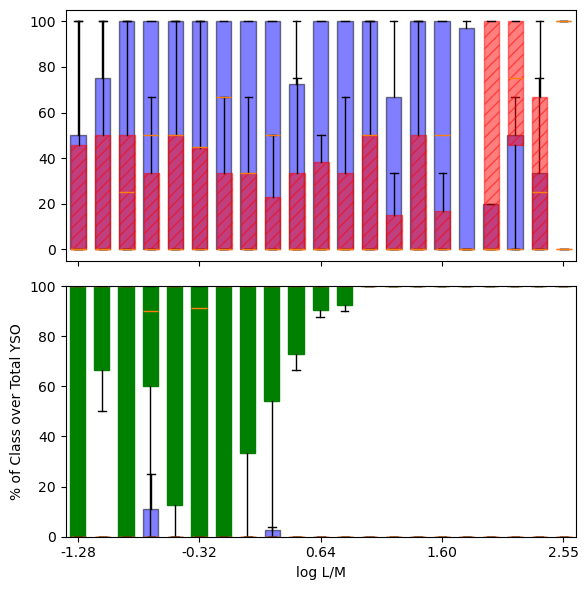

In [401]:

fig, axs = plt.subplots(2,1,figsize=(6,6),tight_layout=True,sharex=True)

for idx in range(2):

    if idx == 0:
        x1, y1 = np.array(data_1[0]), np.array(data_1[1])
        x2, y2 = np.array(data_2[0]), np.array(data_2[1])
    else:
        x1, y1 = np.array(data_4[0]), np.array(data_4[1])
        x2, y2 = np.array(data_5[0]), np.array(data_5[1])
    x3, y3 = np.array(data_3[0]), np.array(data_3[1])

    min = np.min([np.min(x1),np.min(x2),np.min(x3)])
    max = np.max([np.max(x1),np.max(x2),np.max(x3)])

    print(min)
    print(max)
    n_bins = 20
    step = (max-min)/(n_bins+1)
    bins = np.arange(min, max+step, step)

    groups1, groups2, groups3 = [], [], []
    pos1, pos2, pos3 = [], [], []

    offset = step/50  # spacing between boxplots

    for i in range(len(bins) - 1):
        mask1 = (x1 >= bins[i]) & (x1 < bins[i+1])
        mask2 = (x2 >= bins[i]) & (x2 < bins[i+1])
        mask3 = (x3 >= bins[i]) & (x3 < bins[i+1])

        center = (bins[i] + bins[i+1]) / 2

        if np.sum(mask1) > 0:
            pos1.append(center)
            groups1.append(y1[mask1])
            
        if np.sum(mask2) > 0:
            pos2.append(center + offset)
            groups2.append(y2[mask2])
        if np.sum(mask3) > 0:
            pos3.append(center - offset)       
            groups3.append(y3[mask2])


    # Class I

    bp1 = axs[idx].boxplot(
        groups1,
        positions=pos1,
        widths=0.12,
        patch_artist=True,
        showfliers=False
    )

    for box in bp1['boxes']:
        box.set(facecolor='blue', alpha=0.5, edgecolor='black')

    # Class II

    bp2 = axs[idx].boxplot(
        groups2,
        positions=pos2,
        widths=0.12,
        patch_artist=True,
        showfliers=False
    )

    for box in bp2['boxes']:
        box.set(facecolor='red', alpha=0.5, edgecolor='red',hatch='///',linewidth=1)


# Class 0

bp0 = axs[1].boxplot(
    groups3,
    positions=pos3,
    widths=0.12,
    patch_artist=True,
    showfliers=False
)

for box in bp0['boxes']:
    box.set(facecolor='green', edgecolor='green',hatch='///',zorder=-1)


plt.xlim(min,max)
plt.ylim([0,100])

plt.xlabel('log L/M')
plt.ylabel('% of Class over Total YSO')

ticks = pos1[::5]

plt.xticks(ticks, [f"{t:.2f}" for t in ticks])


plt.show()

In [267]:
print(class_0_20)

[[np.float64(-0.7658434986502473), np.float64(220.1), np.float64(1283.7), np.float64(3670.0), np.float64(25.8), np.float64(2.56890873015873e+23), np.float64(0.0)], [np.float64(-1.2404912834206503), np.float64(68.9), np.float64(1198.7), np.float64(3630.0), np.float64(13.9), np.float64(3.3156845238095244e+23), np.float64(0.0)], [np.float64(-0.03689804154200282), np.float64(435.3), np.float64(473.9), np.float64(1860.0), np.float64(47.3), np.float64(6.362529761904762e+23), np.float64(0.0)], [np.float64(1.084519261623048), np.float64(2627.7), np.float64(216.3), np.float64(1780.0), np.float64(37.6), np.float64(3.7338789682539685e+23), np.float64(0.0)], [np.float64(-0.43227309023219107), np.float64(316.3), np.float64(855.8), np.float64(5280.0), np.float64(30.5), np.float64(1.881875e+23), np.float64(0.0)], [np.float64(-0.01102401186693966), np.float64(606.8), np.float64(622.4), np.float64(3530.0), np.float64(40.3), np.float64(2.6585218253968255e+23), np.float64(-300.0)], [np.float64(-0.4346112

In [268]:
print(class_II_60)

[[np.float64(-0.7658434986502473), np.float64(220.1), np.float64(1283.7), np.float64(3670.0), np.float64(25.8), np.float64(2.56890873015873e+23), np.float64(50.0)], [np.float64(-1.2404912834206503), np.float64(68.9), np.float64(1198.7), np.float64(3630.0), np.float64(13.9), np.float64(3.3156845238095244e+23), np.float64(50.0)], [np.float64(-0.03689804154200282), np.float64(435.3), np.float64(473.9), np.float64(1860.0), np.float64(47.3), np.float64(6.362529761904762e+23), np.float64(50.0)], [np.float64(1.084519261623048), np.float64(2627.7), np.float64(216.3), np.float64(1780.0), np.float64(37.6), np.float64(3.7338789682539685e+23), np.float64(50.0)], [np.float64(-0.43227309023219107), np.float64(316.3), np.float64(855.8), np.float64(5280.0), np.float64(30.5), np.float64(1.881875e+23), np.float64(50.0)], [np.float64(-0.01102401186693966), np.float64(606.8), np.float64(622.4), np.float64(3530.0), np.float64(40.3), np.float64(2.6585218253968255e+23), np.float64(50.0)], [np.float64(-0.4346

In [269]:
print( np.array(class_0_20) - np.array(class_II_60))

[[   0.    0.    0. ...    0.    0.  -50.]
 [   0.    0.    0. ...    0.    0.  -50.]
 [   0.    0.    0. ...    0.    0.  -50.]
 ...
 [   0.    0.    0. ...    0.    0.  -50.]
 [   0.    0.    0. ...    0.    0.  -50.]
 [   0.    0.    0. ...    0.    0. -350.]]


In [245]:
len(class_0_20)

1017

In [246]:
len(class_I_60)

1017

In [247]:
len(class_II_60)

1017

In [248]:
class_II_20

[[np.float64(-0.01102401186693966),
  np.float64(2.783045572114693),
  np.float64(2.7940695839816323),
  np.float64(3530.0),
  np.float64(40.3),
  np.float64(2.6585218253968255e+23),
  np.float64(20.0)],
 [np.float64(1.7034947063083985),
  np.float64(3.6519076720869994),
  np.float64(1.948412965778601),
  np.float64(2640.0),
  np.float64(55.5),
  np.float64(1.0454861111111111e+23),
  np.float64(25.0)],
 [np.float64(-0.4986821723630566),
  np.float64(2.48826861549546),
  np.float64(2.9869507878585164),
  np.float64(3570.0),
  np.float64(23.4),
  np.float64(4.45078373015873e+23),
  np.float64(16.666666666666664)],
 [np.float64(-0.2868332020427903),
  np.float64(1.9978230807457256),
  np.float64(2.2846562827885157),
  np.float64(3190.0),
  np.float64(22.0),
  np.float64(1.5831646825396828e+23),
  np.float64(40.0)],
 [np.float64(1.1756037840519975),
  np.float64(3.931859432806231),
  np.float64(2.7562556487542333),
  np.float64(3820.0),
  np.float64(42.5),
  np.float64(3.0468452380952385e+

In [249]:
len(class_I_60)

1017

In [ ]:
print(len())

1017


In [254]:
mask = np.array(class_I_60) > 0

print(len(mask[mask]))

6167


In [307]:
data_1[1]

[np.float64(50.0),
 np.float64(0.0),
 np.float64(100.0),
 np.float64(0.0),
 np.float64(50.0),
 np.float64(60.0),
 np.float64(0.0),
 np.float64(66.66666666666666),
 np.float64(100.0),
 np.float64(0.0),
 np.float64(66.66666666666666),
 np.float64(25.0),
 np.float64(71.42857142857143),
 np.float64(50.0),
 np.float64(100.0),
 np.float64(80.0),
 np.float64(0.0),
 np.float64(50.0),
 np.float64(100.0),
 np.float64(33.33333333333333),
 np.float64(60.0),
 np.float64(50.0),
 np.float64(100.0),
 np.float64(0.0),
 np.float64(50.0),
 np.float64(50.0),
 np.float64(50.0),
 np.float64(100.0),
 np.float64(85.71428571428571),
 np.float64(83.33333333333334),
 np.float64(100.0),
 np.float64(50.0),
 np.float64(100.0),
 np.float64(50.0),
 np.float64(83.33333333333334),
 np.float64(50.0),
 np.float64(100.0),
 np.float64(100.0),
 np.float64(0.0),
 np.float64(100.0),
 np.float64(66.66666666666666),
 np.float64(90.0),
 np.float64(100.0),
 np.float64(100.0),
 np.float64(50.0),
 np.float64(0.0),
 np.float64(0.0),

In [308]:
data_2[1]

[np.float64(50.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(50.0),
 np.float64(40.0),
 np.float64(0.0),
 np.float64(33.33333333333333),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(33.33333333333333),
 np.float64(75.0),
 np.float64(28.57142857142857),
 np.float64(50.0),
 np.float64(0.0),
 np.float64(20.0),
 np.float64(100.0),
 np.float64(50.0),
 np.float64(0.0),
 np.float64(66.66666666666666),
 np.float64(40.0),
 np.float64(50.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(50.0),
 np.float64(50.0),
 np.float64(50.0),
 np.float64(0.0),
 np.float64(14.285714285714285),
 np.float64(16.666666666666664),
 np.float64(0.0),
 np.float64(50.0),
 np.float64(0.0),
 np.float64(50.0),
 np.float64(16.666666666666664),
 np.float64(50.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(33.33333333333333),
 np.float64(10.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(50.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(14.28571

In [311]:
len(alma_regions[alma_regions['class_I_60'] > 0])

518

In [294]:
len(alma_regions[alma_regions['p1_class_II'] > 0])

0

In [367]:
len(alma_regions[alma_regions['class_I_60'] > 0])

518

In [312]:
len(alma_regions[alma_regions['class_II_60'] > 0])

338

In [313]:
len(alma_regions[alma_regions['class_0_20'] > 0])

822

In [314]:
len(alma_regions[alma_regions['class_I_20'] > 0])

148

In [315]:
len(alma_regions[alma_regions['class_II_20'] > 0])

7

L_M: -1.371926893096385, 2.6490899105719588
L: 0.9822712330395684, 5.719365515333529
M: 1.0644579892269184, 4.094289406693462
dist: 2.832508912706236, 4.201670179646581
T: 1.1172712956557642, 2.0542299098633974
NH_2: 21.776280219067235, 24.329556265204335


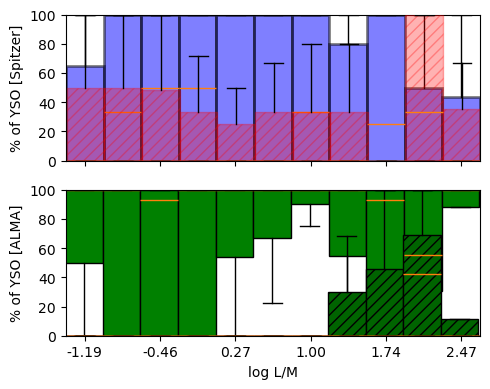

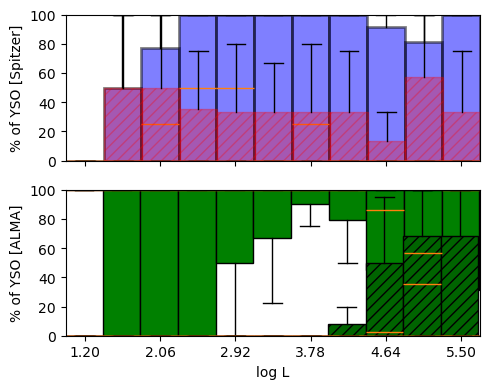

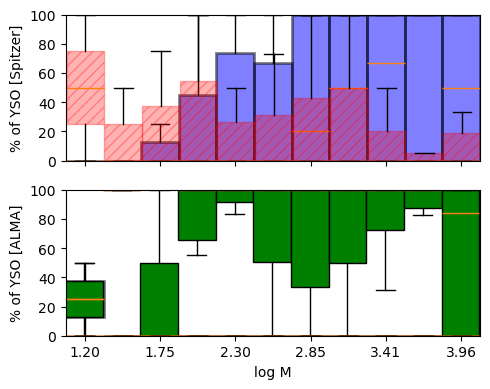

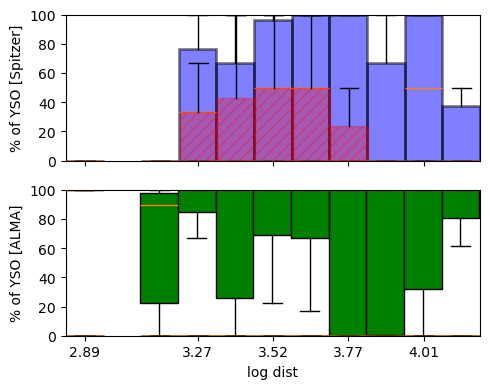

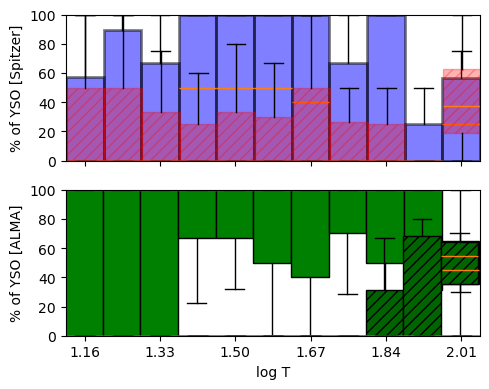

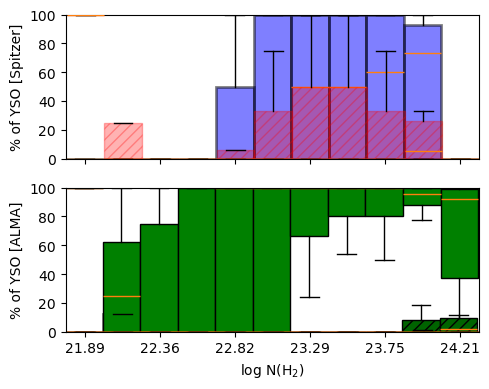

In [471]:
cat='glimpse_s07'
skipflag = []

class_I_60 = []
class_II_60 = []
class_0_20 = []
class_I_20 = []
class_II_20 = []
radio_20 = []

for region in alma_regions:

    if (
          region['MASS'] == -999 or
          region['LUM'] == -999 or
          region['TBOL'] == -999 or 
          region['DIST_AG'] == -999 or
          region['NODEC_SURFD'] == -999
    ) or (
        (
          region['MASS'] == 0 or
          region['LUM'] == 0 or
          region['TBOL'] == 0 or 
          region['DIST_AG'] == 0 or
          region['NODEC_SURFD'] == 0
    )
    ):
        
        skipflag.append(region['INTERNAL_ID'])
        continue
      
    L_M = np.log10(region['LUM'] / region['MASS'])
    L = np.log10(region['LUM'])
    M = np.log10(region['MASS'])
    dist = np.log10(region['DIST_AG'])
    T = np.log10(region['TBOL'])
    NH_2 = np.log10(region['NODEC_SURFD']*SURFD_to_nH2)


    class_I_60.append([L_M,L,M,dist,T,NH_2, region['rat_class_I_60']*100])
    class_II_60.append([L_M,L,M,dist,T,NH_2, region['rat_class_II_60']*100])
    class_0_20.append([L_M,L,M,dist,T,NH_2, region['rat_class_0_20']*100])
    class_I_20.append([L_M,L,M,dist,T,NH_2, region['rat_class_I_20']*100])
    class_II_20.append([L_M,L,M,dist,T,NH_2, region['rat_class_II_20']*100])
    radio_20.append([L_M,L,M,dist,T,NH_2, region['rat_radio_20']*100])

xlabels = ['log L/M', 'log L', 'log M', 'log dist', 'log T', 'log N(H$_2$)']

for idx, plot in enumerate(['L_M','L','M','dist','T','NH_2']):

    fig, axs = plt.subplots(2,1,figsize=(5,4),tight_layout=True,sharex=True)

    color_list = ['blue','red','lightgrey']

    for idx2,data_set in enumerate([[class_I_60,class_II_60,class_0_20,radio_20],[class_I_20,class_II_20,class_0_20,radio_20]]):

        data_1 = [[x[idx] for x in data_set[0]],[x[-1] for x in data_set[0]]]
        data_2 = [[x[idx] for x in data_set[1]],[x[-1] for x in data_set[1]]]
        data_3 = [[x[idx] for x in data_set[2]],[x[-1] for x in data_set[2]]]
        data_4 = [[x[idx] for x in data_set[3]],[x[-1] for x in data_set[3]]]

        x1, y1 = np.array(data_1[0]),np.array(data_1[1])
        x2, y2 = np.array(data_2[0]), np.array(data_2[1])
        x3, y3 = np.array(data_3[0]), np.array(data_3[1])
        x4, y4 = np.array(data_4[0]), np.array(data_4[1])
        
        if idx2 == 0:
            min = np.min([np.min(x1),np.min(x2),np.min(x3),np.min(x4)])
            max = np.max([np.max(x1),np.max(x2),np.max(x3),np.max(x4)])
            n_bins = 10
            step = (max-min)/(n_bins+1)
            bins = np.arange(min, max+step, step)

        groups1, groups2, groups3, groups4 = [], [], [], []
        pos1, pos2, pos3, pos4 = [], [], [], []

        offset = step/50  # spacing between boxplots

        for i in range(len(bins) - 1):
            mask1 = (x1 >= bins[i]) & (x1 < bins[i+1])
            mask2 = (x2 >= bins[i]) & (x2 < bins[i+1])
            mask3 = (x3 >= bins[i]) & (x3 < bins[i+1])
            mask4 = (x4 >= bins[i]) & (x4 < bins[i+1])
            
            center = (bins[i] + bins[i+1]) / 2

            if np.sum(mask1) > 0:
                pos1.append(center)
                groups1.append(y1[mask1])
                
            if np.sum(mask2) > 0:
                pos2.append(center + offset)
                groups2.append(y2[mask2])
            if np.sum(mask3) > 0:
                pos3.append(center - offset)       
                groups3.append(y3[mask3])
            if np.sum(mask4) > 0:
                pos4.append(center - 2*offset)       
                groups4.append(y4[mask4])

        # Class I

        bp1 = axs[idx2].boxplot(
            groups1,
            positions=pos1,
            widths=step,
            patch_artist=True,
            showfliers=False,
            zorder=2
        )

        for box in bp1['boxes']:
            box.set(facecolor='blue', alpha=0.5, edgecolor='black',linewidth=2,zorder=0)

        # Class II

        bp2 = axs[idx2].boxplot(
            groups2,
            positions=pos2,
            widths=step,
            patch_artist=True,
            showfliers=False,
            zorder=3
        )

        for box in bp2['boxes']:
            box.set(facecolor='red', alpha=0.3, edgecolor='red',hatch='///',linewidth=1)

    print(f'{plot}: {np.min(x4)}, {np.max(x4)}')
    # Class 0

    bp0 = axs[1].boxplot(
        groups3,
        positions=pos3,
        widths=step,
        patch_artist=True,
        showfliers=False,
        zorder=1
    )

    for box in bp0['boxes']:
        box.set(facecolor='green', edgecolor='black')

    bp0_radio = axs[1].boxplot(
        groups4,
        positions=pos4,
        widths=step,
        patch_artist=True,
        showfliers=False,
        zorder=1
    )

    for box in bp0_radio['boxes']:
        box.set(facecolor='darkgreen', edgecolor='black',hatch='///')


    axs[0].set_xlim(min,max)
    axs[0].set_ylim([0,100])
    axs[1].set_ylim([0,100])

    axs[1].set_xlabel(f'{xlabels[idx]}')
    axs[0].set_ylabel(r'% of YSO [Spitzer]')
    axs[1].set_ylabel(r'% of YSO [ALMA]')

    ticks = pos1[::2]

    axs[1].set_xticks(ticks, [f"{t:.2f}" for t in ticks])
    if idx2 == 1:
        fig.savefig('../output/figures/'+cat+'/results_'+plot+'.pdf',format='pdf',dpi=300)

In [381]:
spitzer_sources = Table.read('../output/tables/glimpse_s07/spitzer_sources_to_analyze.tbl',format='ascii.ipac')
alma_regions = Table.read('../output/tables/glimpse_s07/alma_regions_to_analyze.tbl',format='ascii.ipac')

In [382]:
len(spitzer_sources['p1_class_I'][spitzer_sources['p1_class_I'] == 'True'])

1072

In [383]:
counter = 0
for region in alma_regions:
    region_id = region['INTERNAL_ID']
    counter = counter + len(spitzer_sources['p1_class_I'][(spitzer_sources['p1_class_I'] == 'True') & (spitzer_sources['internal_id_01'] == region_id)])

print(counter)

1072


In [390]:
print(np.sum(alma_regions['class_0_20']))

5960


In [416]:
for idx2,data_set in enumerate([[class_I_60,class_II_60,class_0_20],[class_I_20,class_II_20,class_0_20]]):

    print(data_set[0][0])

[np.float64(-0.7658434986502473), np.float64(220.1), np.float64(1283.7), np.float64(3670.0), np.float64(25.8), np.float64(2.56890873015873e+23), np.float64(50.0)]
[np.float64(-0.7658434986502473), np.float64(220.1), np.float64(1283.7), np.float64(3670.0), np.float64(25.8), np.float64(2.56890873015873e+23), np.float64(0.0)]


In [436]:
for idx2,data_set in enumerate([[class_I_60,class_II_60,class_0_20],[class_I_20,class_II_20,class_0_20]]):

    data_1 = [[x[1] for x in data_set[0]],[x[-1] for x in data_set[0]]]
    data_2 = [[x[1] for x in data_set[1]],[x[-1] for x in data_set[1]]]
    data_3 = [[x[1] for x in data_set[2]],[x[-1] for x in data_set[2]]]
    
    print(f'{idx2}:\n\n{np.array(data_1)}\n\n{data_2}\n\n{data_3}\n\n')
    print(f'{idx2}: \n\n {np.sum(np.where(np.isnan(np.array(data_1))))}')
    print(f'{idx2}:\n\n{np.min(data_1)}\n\n{np.min(data_2)}\n\n{np.min(data_3)}\n\n')

0:

[[220.1         68.9        435.3        ...   3.39112926   1.62838893
    2.97464983]
 [ 50.           0.         100.         ...  50.          50.
  100.        ]]

[[np.float64(220.1), np.float64(68.9), np.float64(435.3), np.float64(2627.7), np.float64(316.3), np.float64(606.8), np.float64(528.0), np.float64(181.8), np.float64(4486.5), np.float64(85.7), np.float64(307.8), np.float64(178.4), np.float64(99.5), np.float64(87.9), np.float64(8547.9), np.float64(15764.7), np.float64(76358.0), np.float64(869.6), np.float64(14954.8), np.float64(2023.6), np.float64(333.4), np.float64(174.8), np.float64(5745.4), np.float64(1056.6), np.float64(2297.0), np.float64(-999.0), np.float64(6285.8), np.float64(14055.0), np.float64(897.7), np.float64(7930.1), np.float64(30160.6), np.float64(329.0), np.float64(398.3), np.float64(76.5), np.float64(1265.5), np.float64(55134.6), np.float64(3679.9), np.float64(7982.1), np.float64(37411.7), np.float64(2867.6), np.float64(909.4), np.float64(203.7), np.fl

In [438]:
len(data_1[0])

13191